<a href="https://colab.research.google.com/github/rifkipadilah7/Landding-page-sepatulokal/blob/main/TugasUtsPraktikumJst.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#nama rifki padilah
#nim 240102114

#import library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
#membaca dataset
data = {
    "ID Mahasiswa": [f"MHS{str(i).zfill(2)}" for i in range(1, 25)],
    "Kehadiran": [14, 13, 14, 12, 13, 14, 13, 14,
                  9, 8, 10, 9, 8, 10, 9, 11,
                  4, 3, 5, 2, 4, 3, 5, 6],
    "Akses LMS": [85, 90, 78, 82, 95, 88, 80, 92,
                  45, 50, 38, 42, 55, 48, 40, 52,
                  10, 8, 15, 5, 12, 9, 14, 18],
    "Pengumpulan Tugas": [10, 10, 9, 10, 9, 10, 9, 10,
                          6, 5, 6, 7, 5, 6, 5, 7,
                          1, 2, 1, 0, 2, 1, 2, 3],
}
df = pd.DataFrame(data)


In [3]:
#menampilkan data mahasiswa
print("Data Mahasiswa:")
print(df.to_string(index=False))
print("\nInformasi dataset:")
print(f"Jumlah data  : {df.shape[0]} mahasiswa")
print(f"Missing value: {df.isnull().sum().sum()}")
print("\nStatistik deskriptif:")
print(df.describe().round(2))


Data Mahasiswa:
ID Mahasiswa  Kehadiran  Akses LMS  Pengumpulan Tugas
       MHS01         14         85                 10
       MHS02         13         90                 10
       MHS03         14         78                  9
       MHS04         12         82                 10
       MHS05         13         95                  9
       MHS06         14         88                 10
       MHS07         13         80                  9
       MHS08         14         92                 10
       MHS09          9         45                  6
       MHS10          8         50                  5
       MHS11         10         38                  6
       MHS12          9         42                  7
       MHS13          8         55                  5
       MHS14         10         48                  6
       MHS15          9         40                  5
       MHS16         11         52                  7
       MHS17          4         10                  1
       MHS18

In [4]:
#preproccesing: normalisasi (standarscaler)
fitur = ["Kehadiran", "Akses LMS", "Pengumpulan Tugas"]
X = df[fitur].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("5 data pertama setelah normalisasi:")
print(np.round(X_scaled[:5], 3))

5 data pertama setelah normalisasi:
[[1.294 1.194 1.275]
 [1.041 1.355 1.275]
 [1.294 0.969 0.981]
 [0.789 1.097 1.275]
 [1.041 1.517 0.981]]


K=2 | Inertia=19.106 | Silhouette=0.629
K=3 | Inertia=3.249 | Silhouette=0.743
K=4 | Inertia=2.576 | Silhouette=0.582
K=5 | Inertia=1.901 | Silhouette=0.453
K=6 | Inertia=1.647 | Silhouette=0.339
K=7 | Inertia=1.410 | Silhouette=0.305


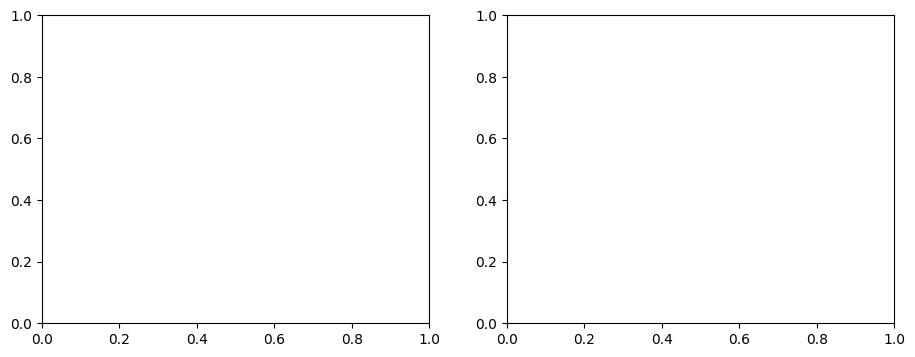

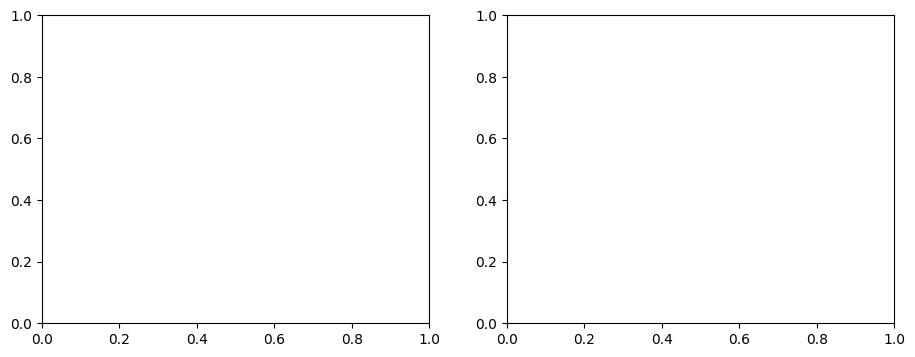

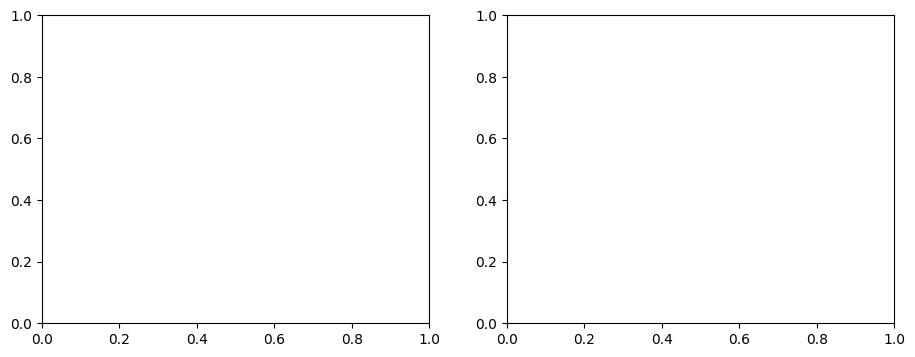

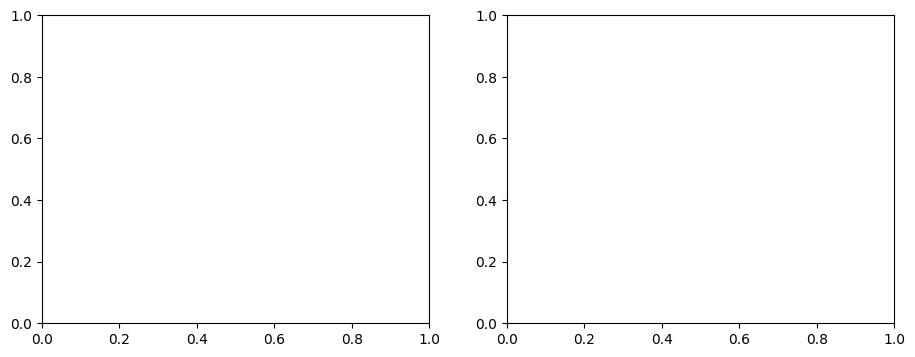

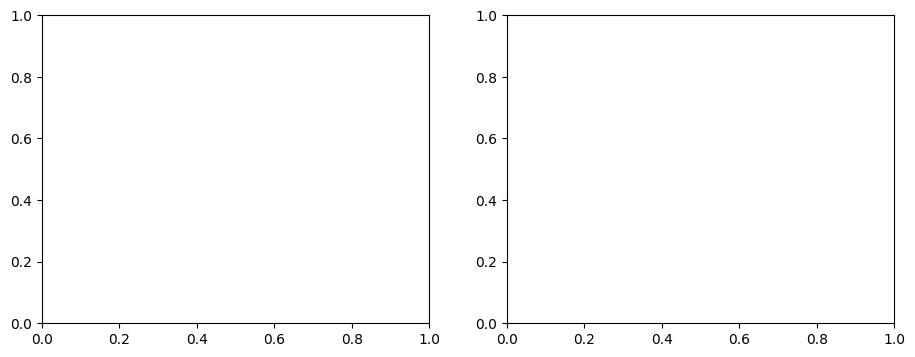

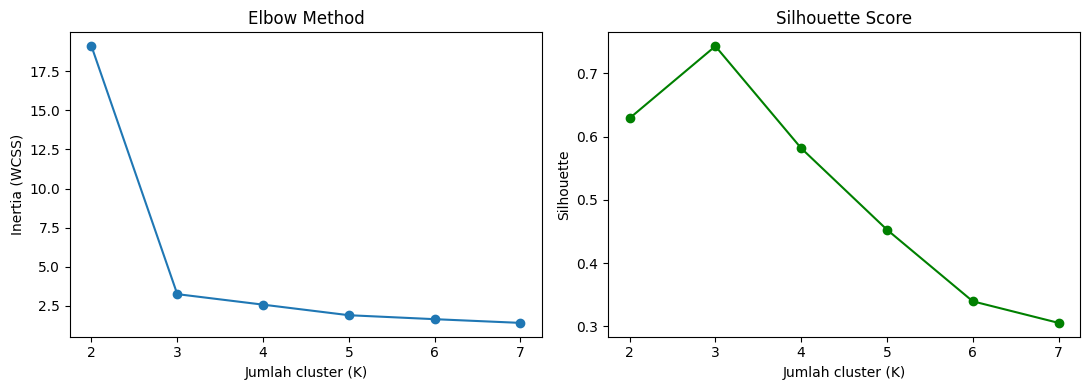

K dengan silhouette tertinggi: 3


In [5]:

#Menentukan jumlah cluster (K): Elbow Method + Silhouette Score
k_range = range(2, 8)
inertia, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, labels))
    print(f"K={k} | Inertia={km.inertia_:.3f} | Silhouette={sil[-1]:.3f}")

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(k_range), inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Jumlah cluster (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[1].plot(list(k_range), sil, marker="o", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Jumlah cluster (K)")
ax[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

K_TERBAIK = list(k_range)[int(np.argmax(sil))]
print(f"K dengan silhouette tertinggi: {K_TERBAIK}")


In [6]:
#Proses K-Means clustering
K = 3  # sesuai pembagian aktif / sedang / kurang aktif (ubah jika perlu)
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)
print(f"Silhouette Score (K={K}): {silhouette_score(X_scaled, df['Cluster']):.3f}")

Silhouette Score (K=3): 0.743


In [7]:
#Menampilkan hasil cluster setiap mahasiswa
print(df.sort_values("Cluster").to_string(index=False))
print("\nJumlah anggota tiap cluster:")
print(df["Cluster"].value_counts().sort_index())


ID Mahasiswa  Kehadiran  Akses LMS  Pengumpulan Tugas  Cluster
       MHS16         11         52                  7        0
       MHS15          9         40                  5        0
       MHS14         10         48                  6        0
       MHS13          8         55                  5        0
       MHS12          9         42                  7        0
       MHS11         10         38                  6        0
       MHS10          8         50                  5        0
       MHS09          9         45                  6        0
       MHS24          6         18                  3        1
       MHS23          5         14                  2        1
       MHS22          3          9                  1        1
       MHS21          4         12                  2        1
       MHS20          2          5                  0        1
       MHS19          5         15                  1        1
       MHS18          3          8                  2  

In [8]:
#Memberi nama cluster berdasarkan rata-rata aktivitas
rata = df.groupby("Cluster")[fitur].mean()
urutan = rata.sum(axis=1).rank(ascending=False).astype(int)  # 1 = paling aktif
nama_tingkat = {1: "Aktif", 2: "Sedang", 3: "Kurang Aktif"}
nama_cluster = {c: nama_tingkat.get(urutan[c], f"Cluster {c}") for c in rata.index}
df["Kategori"] = df["Cluster"].map(nama_cluster)


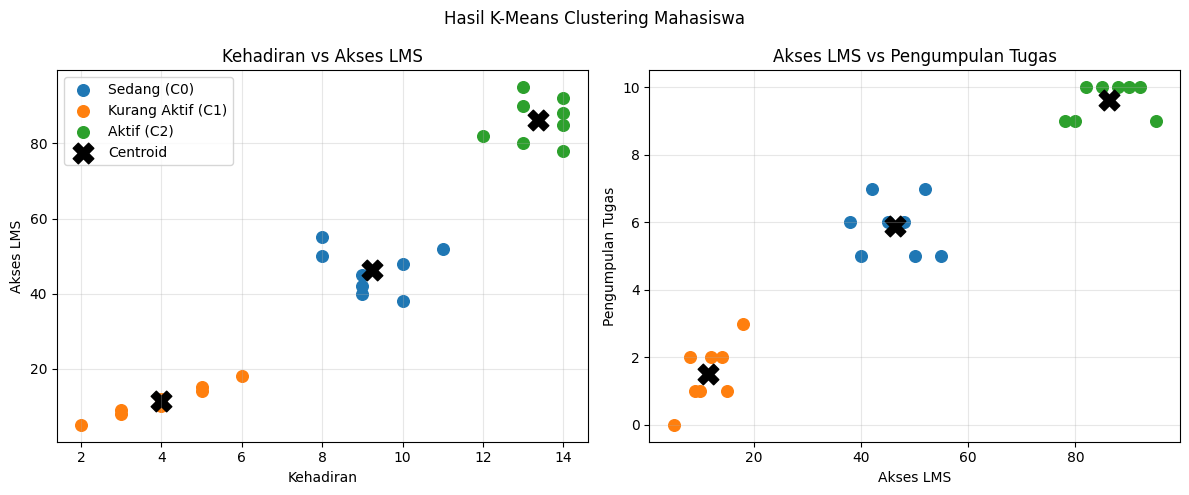

In [9]:
#Visualisasi hasil clustering
centroid = scaler.inverse_transform(kmeans.cluster_centers_)  # skala asli
warna = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

pasangan = [("Kehadiran", "Akses LMS", 0, 1),
            ("Akses LMS", "Pengumpulan Tugas", 1, 2)]
for a, (fx, fy, ix, iy) in zip(ax, pasangan):
    for c in sorted(df["Cluster"].unique()):
        sub = df[df["Cluster"] == c]
        a.scatter(sub[fx], sub[fy], c=warna[c], s=70,
                  label=f"{nama_cluster[c]} (C{c})")
    a.scatter(centroid[:, ix], centroid[:, iy], c="black", marker="X",
              s=220, label="Centroid")
    a.set_xlabel(fx)
    a.set_ylabel(fy)
    a.set_title(f"{fx} vs {fy}")
    a.grid(alpha=0.3)
ax[0].legend()
plt.suptitle("Hasil K-Means Clustering Mahasiswa")
plt.tight_layout()
plt.show()

Ringkasan statistik tiap cluster:
             Kehadiran         Akses LMS         Pengumpulan Tugas        
                  mean min max      mean min max              mean min max
Kategori                                                                  
Aktif            13.38  12  14     86.25  78  95              9.62   9  10
Kurang Aktif      4.00   2   6     11.38   5  18              1.50   0   3
Sedang            9.25   8  11     46.25  38  55              5.88   5   7

=== INTERPRETASI ===
- Aktif (8 mahasiswa): rata-rata kehadiran 13.4, akses LMS 86.2, tugas terkumpul 9.6
- Kurang Aktif (8 mahasiswa): rata-rata kehadiran 4.0, akses LMS 11.4, tugas terkumpul 1.5
- Sedang (8 mahasiswa): rata-rata kehadiran 9.2, akses LMS 46.2, tugas terkumpul 5.9


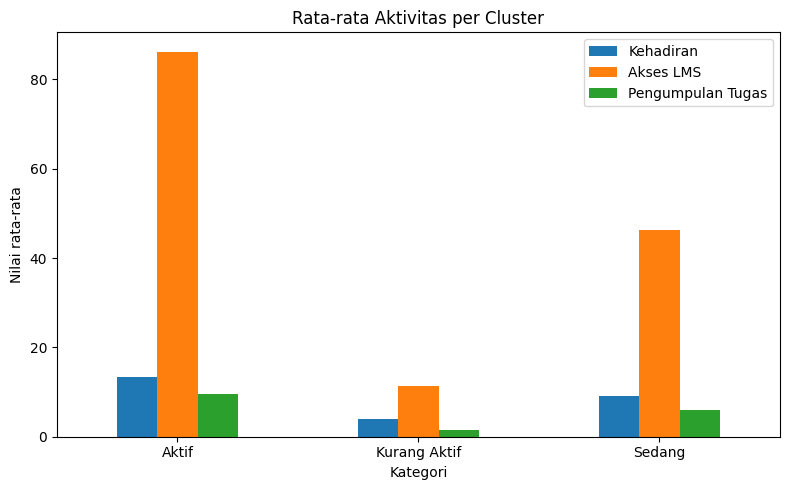

In [10]:

#Analisis karakteristik setiap cluster
analisis = df.groupby("Kategori")[fitur].agg(["mean", "min", "max"]).round(2)
print("Ringkasan statistik tiap cluster:")
print(analisis)

print("\n=== INTERPRETASI ===")
rata_kat = df.groupby("Kategori")[fitur].mean().round(1)
for kat, baris in rata_kat.iterrows():
    n = (df["Kategori"] == kat).sum()
    print(f"- {kat} ({n} mahasiswa): rata-rata kehadiran {baris['Kehadiran']}, "
          f"akses LMS {baris['Akses LMS']}, tugas terkumpul {baris['Pengumpulan Tugas']}")

# Diagram batang rata-rata fitur per cluster
rata_kat.plot(kind="bar", figsize=(8, 5))
plt.title("Rata-rata Aktivitas per Cluster")
plt.ylabel("Nilai rata-rata")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
